## 1. 인공신경망의 시작 : 퍼셉트론  
> 인공신경망이란? (Artificial Neural Network) : 우리 뇌의 신경망을 모방한 모델  
1. 입력들을 받아 각각 가중치와 편향을 적용  
2. 종합한 값을 활성화 함수에 넘긴다. 이때 활성화 함수는 임계값을 기준으로 함  
    - 기준 미달이면? -> 0에 가깝게 죽여서 보냄  
    - 기준 통과면? -> 유의미한 값으로 살려서 보냄  
3. output 출력  

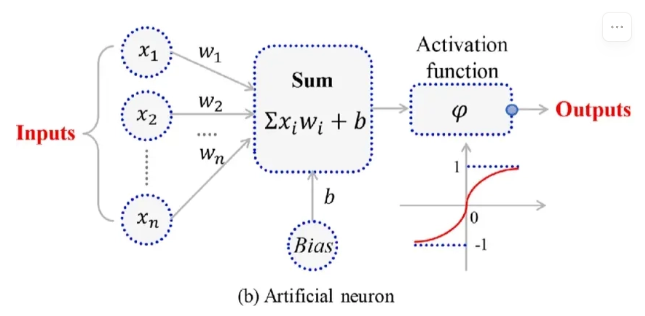  
구조도

> 퍼셉트론(Perceptron) : 초기 형태의 인공신경망, 신경망(딥러닝)의 기원이 되는 선형 이진 분류기  

퍼셉트론의 출력값을 구하는 절차 : 입력 -> 가중합 -> 활성화 함수 -> 출력
1. 입력값과 가중치를 곱함 -> $x_1w_1$  
2. 곱한 값들의 총합 계산 -> $x_1w_1 + x_2w_2 + ... + x_nw_n$ (편향을 더해줄지는 선택)  
3. 총합이 임계값 $\theta$을 넘으면 1, 넘지 않으면 0을 출력(활성화 함수는 step function)
**활성화 함수 : 임계값 초과여부에 따라 출력값을 결정. 사용하는 활성화 함수에 따라 출력값이 변화**  
**Training(학습) : 원하는 출력값을 내보내도록 가중치를 조정해가는 작업**  


### 단층 퍼셉트론과 그 한계  
> 단층 퍼셉트론 : 단순히 입력층과 츨력충으로만 이루어진 퍼셉트론, 값을 보내는 단계와 받아서 출력하는 단계로만 이루어짐

단층 퍼셉트론 이용시 AND, NAND, OR 논리게이트를 쉽게 구현할 수 있음
> 논리게이트란?  
 - 디지털, 회로에서 기본직인 논리 연산 수행에 사용되는 구성 요소  
 - 게이트 연산에 쓰이는 것은 n개의 입력값과 하나의 출력값  
 - AND, OR, NOT, NAND, NOR, XOR 등 다양한 종류 존재, 이러한 논리게이트를 조합하여 복잡한 논리 회로 구성 가능  

**대표적인 논리게이트**  
EXAMPLE - AND 게이트  
입력값이 모두 1인 경우에만 출력값이 1이 나오는 구조  

| $x_1$ | $x_2$ | $y$ |  
|---|---|---|  
| 0 | 0 | 0 |  
| 0 | 1 | 0 |  
| 1 | 0 | 0 |  
| 1 | 1 | 1 |  

이때, AND 게이트를 구성하는 가중치와 편향 $w_1, w_2, b$에는 여러 조합이 있을 수 있다!  
*e.g. [0.5, 0.5, -0.7], [1.0, 1.0, -1.0] ... (임계값 0)*  

같은 원리로 다른 게이트들도 구성 가능  

| 게이트 | 조건 | 가중치 편향 예시[$w_1, w_2, b$] (임계값 0) |  
|---|---|---|  
| AND | 둘 다 1일때만 1 | [0.5, 0.5, -0.7] |  
| OR | 둘 다 0일때만 0 | [0.6, 0.6, -0.5] |  
| NAND | 둘 다 1일때만 0 | [-0.5, -0.5, 0.7] |  
| XOR | 서로 다를때만 1 | 가능한 조합 X |  


#### 단층 퍼센트론의 한계   
**XOR 게이트를 구현할 수 없다!**  
퍼셉트론은 입력값과 가중치의 선형 결합으로 이루어진 구조이기 때문에, 단층 퍼셉트론은 직선 하나로 두 영역을 나눌 수 있는 선형 분류 문제에 대해서만 구현가능  

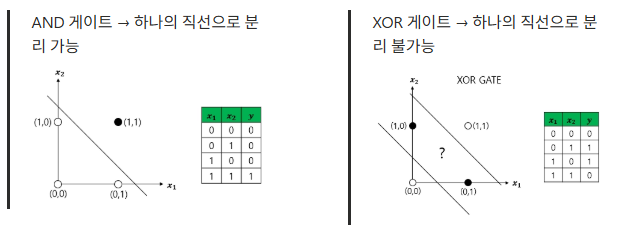  

XOR게이트는 직선이 아닌 곡선/비선형 영역으로 분리해야만 구현할 수 있다!  
그렇다면 퍼셉트론을 여러계층으로 쓰면? -> 가능!  



###  다층 퍼셉트론  (Multi-Layer Perceptron, MLP)  
XOR 게이트는 기존의 AND, NAND, OR게이트를 조합하면 구현 가능 *i.e. 퍼셉트론의 층을 더 쌍으면 가능*  
주의 : 단순히 층을 많이 쌓는것만으로는 비선형성이 생기지 않음. 활성화 함수 없이 가중합과 편향만 계산한다면, 여러층을 연결해도 결국 하나의 연산으로 합쳐진다.  

그렇다면 다층 퍼셉트론은 XOR을 어떻게 구현?  
은닉층에서 비선형 활성화 함수를 적용해 새로운 특징을 만들고, 다음층에서 그 특징들을 조합.  
*e.g. 은닉층의 두 뉴런이 각각 NAND, OR을 계산하고, 출력층이 두 결과에 AND를 적용하면 XOR이 도출됨*  

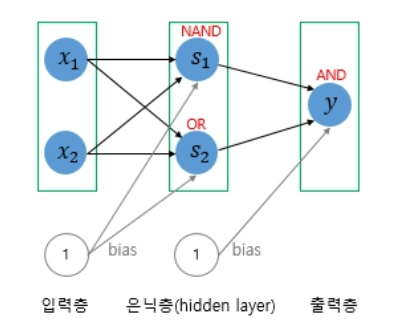  

XOR보다 더 복잡한 문제 해결시 중간에 은닉층을 더 많이 추가하면 구현 가능



## 딥러닝 모델의 학습 방법  

### 1. 순전파와 역전파(Forward & Backward Propagation)  

학습 알고리즘의 기본 구조  
1. 순전파를 통해 입력값으로부터 예측 수행  
2. 오차계산을 통해 예측 정확도 측정  
3. 역전파를 통해 출력층에서 다시 입력층으로 오차 전달  
4. 가중치 업데이트  
5. 1~4를 반복 (마치 오답노트 적어서 풀이하는 느낌)  
위의 과정을 반복하다 보면 오차값이 0에 수렴!  

그렇다면 순전파/역전파의 과정은 어떻게 일어나는가?  
-> 연쇄법칙(Chain Rule)을 통해서 발생  

> 연쇄 법칙 : 합성함수의 미분은 각 함수의 미분의 곱으로 표현 가능  

딥러닝에선 입력값이 여러 은닉층을 거친 후 최종 출력값이 도출, 이때 입력값이 최종 출력에 얼마나 영향을 미쳤는지 계산하려면 각 층이 다음 층에 미친 영향을 순서대로 곱해나가야 함(변화율의 곱)  

$\frac{\partial L}{\partial w_1} = \frac{\partial L}{\partial a_n} \times \cdots \times \frac{\partial a_2}{\partial a_1} \times \frac{\partial a_1}{\partial w_1}$

- 딥러닝 모델의 성능을 높이려면 모델의 오차를 계산해 순전파와 역전파를 활용해서 오차를 줄이는 과정 필요  
- 손실함수 = 예측값과 실제값의 차이를 수치로 표현  
- 연쇄법칙을 통해 구하는 기울기 = '손실 함수를 줄이기 위해 가중치를 어떻게 바꿀까?'를 알려주는 신호  

**만약 은닉층도 엄청 많고, 각 단계마다 미분값이 1보다 작은 값이라면? 최종 결과는 한없이 0에 가까워진다**  
$0.25 \times 0.25 \times 0.25 \times \cdots \approx 0$  
*0.25는 시그모이드 미분의 최댓값*  
즉, 기울기들을 계속해서 곱했더니 결국 기울기가 0이되는 문제 발생  

이러한 기울기 소실 문제가 있으면 앞쪽 층의 가중치가 거의 업데이트 되지 않아서 학습이 제대로 이뤄지지 않는 문제 발생  


### 2. 손실함수(Loss Function)
> 손실함수론? : 모델의 예측이 얼마나 틀렸는지를 수치로 표현하는 방법  
손실함수는 모델이 정확한지 오차를 계산하는 방법 -> 실제값(정답)과 예측값(출력값)의 차이를 계산하는데 사용되는 함수  

**손실함수 종류**  

1. 평균 제곱 오차(Mean Squared Error, MSE)  
$\frac{1}{N}\sum(y-\hat{y})^2$  
예측값이 연속적이고, 예측값과 실제값의 차이를 직접 측정하는 회귀문제에 적합
*e.g. 모델이 예측한 집 가격과 실제 집 가격의 차이를 최소화하는 집 가격 예측*  


2. 이진 크로스 엔트로프(Binary Cross-Entropy, BCE)  
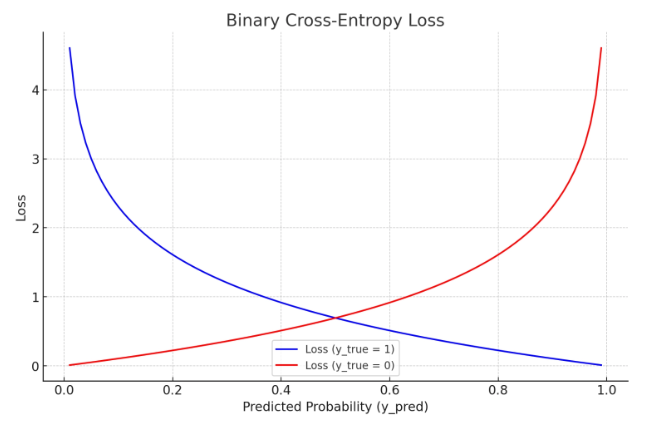  

$L=-(ylog\hat{y}+(1-y)log(1-\hat{y}))$  
이진 분류 문제(로지스틱 회귀)에서 사용하는 손실 함수  

**식이 유도된 과정**  
모델이 예측한 '정답이 1일 확률'을 p라고 하면  
 - 정답이 1이면 -> p가 높아야 잘 예측한 것  
 - 정답이 0이면 -> 1-p가 높아야 잘 예측한 것  

BCE는 실제 정답에 부여한 확률에 -log를 적용한 손실. 정답 확률이 높으면 손실이 작고, 낮으면 손실이 커진다. 

로그가 나온 이유?  
로그는 여러 데이터의 확률을 곱하는 계산을 합으로 바꿔준다. 마이너스 부호는 '확률을 높이는 목표'를 '손실을 줄이는 목표'로 바꾸준다  
$P(y|x)=p^y(1-p)^{1-y}$  
log 적용시 $L=-\log[p^y(1-p)^{1-y}]=-[y\log p+(1-y)\log(1-p)]$

- 실제 정답이 1일때 -> $L=-\log\hat{y}$만 남음  
    - 예측 확률이 1에 가까울수록 -> loss가 0에 가까워짐 = 잘 맞힘  
    - 예측 확률이 0에 가까울수록 -> loss가 급격히 증가(확신했지만 틀림)  
    - e.g. 실제 레이블이 고양이(1)인데 고양이일 예측 확률이 0.1이라면, 모델이 고양이가 아니라고 확신하며 틀린것이므로 손실이 -log(0.1)로 계산되어 큰값을 가짐  

- 실제 정답이 0일때 -> 위의 논리와 반대로 동작  

MSE는 단순히 loss의 크기만 보는 반면, BCE는 얼마나 확신을 가지고 예측했는지도 loss에 반영  


3. 크로스 엔트로피 오차(Cross Entropy Error, CEE)  
$-\sum y\log\hat{y}$  
$y:원-핫 인코딩 값(1,0), \hat{y}:예측값(확률)$  

- 다중 클래스 분류 문제에서 예측 확률이 실제 클래스와 얼마나 일치하는지 평가하는데 적합  
- 2번(이진 크로스 엔트로피)과 거의 유사한 형태이지만 다중분류에서 사용  

| 손실 함수 | 사용 상황 | 예시 |  
|---|---|---|  
| MSE | 회귀 문제 | 주택 가격 예측, 온도 예측, 주식 가격 예측 |  
| BCE | 이진 분류 문제 | 이메일 스팸 필터링(스팸/정상), 질병 진단(양성/음성) |  
| CEE | 다중 클래스 분류 문제 | 손글씨 숫자 인식(MNIST), 이미지 분류(CIFAR-10) |  



### 3. 활성화 함수(Activation Function)  

활성화 함수를 거치는 이유?  
1. 비선형성이 필요 : 활성화 함수가 없으면 층을 아무리 쌓아도 결국 선형 계산의 반복, 1장의 XOR같은 문제 해결 불가능  

2. 미분이 돠어야 한다 : 앞서 역전파는 미분값의 연쇄 곱으로 이루어지기 때문에 활성화 함수는 미분이 가능해야한다. But, Step function의 경우 미분 불가! -> 역전파 불가!  

그래서 활성화 함수는 계단함수 -> 시그모이드 -> ReLU순으로 발전  
Step function : 미분 불가 -> 역전파 자체가 불가  
Sigmoid : 미분가능! but... -> 미분값이 최대 0.25, 이를 여러번 곱할시 기울기 소실 문제 발생  
ReLU : 양수 구간 미분값=1 -> 곱해도 기울기 소실 발생 X  

| | 단층 퍼셉트론 | 다층 퍼셉트론 |  
|---|---|---|  
| 활성화 함수 | 계단 함수 | Sigmoid, ReLU 등 |  
| 출력값 | 0 or 1(binary) | 연속적인 값(확률 or 실수) |  
| 특징 | 선형 문제만 풀 수 있음 | 복잡한 비선형 문제도 학습 가능 |  


#### 활성화 함수 종류  

1. 계단함수 (Heaviside Step Function)  

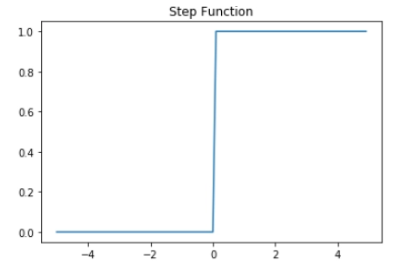  

$$h(x) =
\begin{cases}
1 & \text{if } x \geq 0 \\
0 & \text{o.w.}
\end{cases} $$  

입력값과 가중치의 곱을 모두 더한 뒤, 그 합이 임계점을 넘으면 1, 아니면 0을 출력하는 함수. 주로 단층 퍼셉트론에서 사용  

- 입력신호 : 입력값과 가중치의 곱  
- 출력 신호 : 0 or 1  

임계값은 뉴런이 얼마나 쉽게 활성화 되는지를 제어하고, 가중치는 각 입력 신호가 결과에 미치는 영향력을 제어  


2. 시그모이드 함수(Sigmoid)  

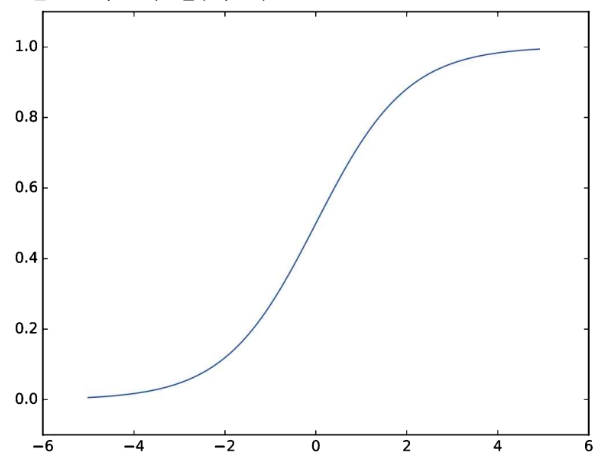  

$f(x) = \frac{1}{1+e^{-x}}$  
 
계단함수는 0 or 1만 출력하는 반면, 시그모이드는 입력 신호를 0과 1사이의 연속적인 값으로 변환하는 비선형 함수  
'확실히 맞다/틀리다'가 아니라 얼마나 확실한지 표현가능하며 미분 역시 가능 
But, 미분값의 최댓값이 0.25, 앞서 언급한 기울기 소실 문제 발생 가능  


3. ReLU(Rectified Linear Unit)  

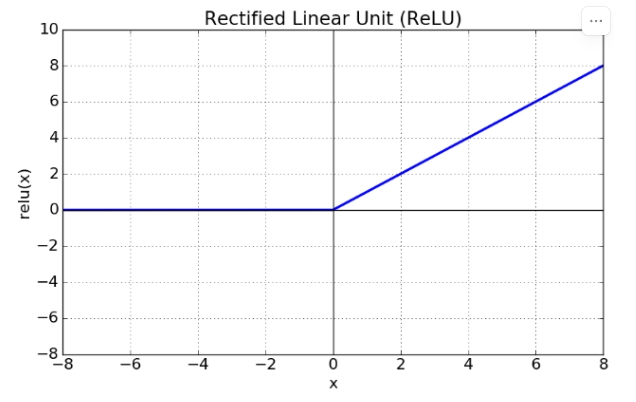  

$f(x) = \max(0,x) $

입력이 0보다 크면 그대로, 0이하면 0을 출력하는 비선형 함수. 단순하지만 딥러닝에서 가장 많이 사용  

Why ReLU?  
1. 계산이 간단하고 효율적 : 0보다 크냐 아니냐만 비교하므로 속도가 빠름  
2. 비선형성 제공 : 음수는 0으로 양수는 그대로 처리하면서 은닉층에 비선형성 추가 가능  
3. 기울기 소실 완화 : 양수 구간에서 미분값이 항상 1이므로 아무리 곱해도 값이 소실되지 않음. 역전파를 안정적으로 전달 가능  



4. Softmax Function  

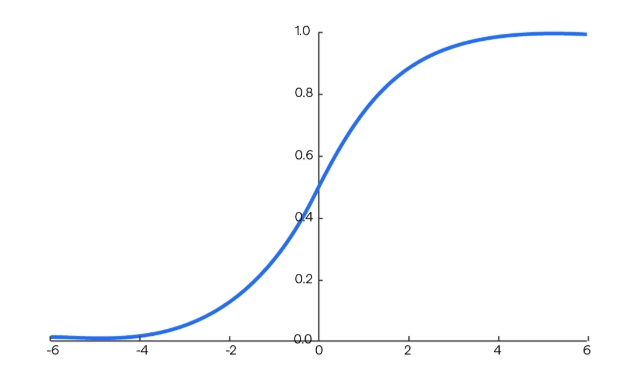  

$f(x_i) = \frac{e^{x_i}}{\sum_j e^{x_j}}$  

각 클래스에 대한 출력값을 확률로 변환하는 함수, 다중 클래스 분류 문제의 출력층에서 사용  
출력값이 모두 0~1 사이이고 전체합이 1이되기 때문에, 각 클래스에 속할 확률을 직접 읽을 수 있음  

ex) 고양이/강아지/새 분류 ->[고양이 0.7, 강아지 0.2, 새 0.1]  


5. 쌍곡탄젠트(tanh()) 함수  

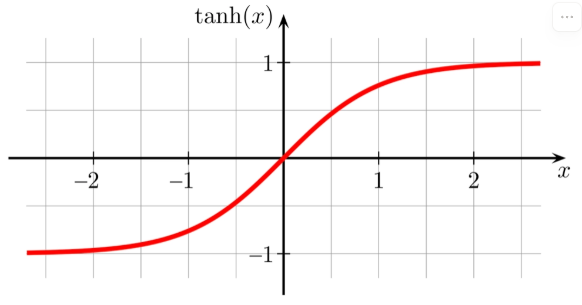  

$f(x) = tanh(x) = \frac{e^x-e^{-x}}{e^x+e^{-x}}  

Sigmoid의 변형으로 출력범위가 -1~1, 출력값의 중심이 0이라 가중치 업데이트가 안정적  
But, 시그모이드와 마찬가지로 입력값이 매우 크거나 작으면 미분값이 0에 가까워져서 기울기 소실 발생  

**활성화 함수 정리**

| 활성화 함수 | 출력 범위 | 주요 사용처 | 장점 | 단점 |
| --- | --- | --- | --- | --- |
| 계단 함수 | 0 or 1 | 단층 퍼셉트론 | 구조가 단순 | 미분 불가 |
| Sigmoid | 0 ~ 1 | 이진 분류 출력층 | 확률로 해석 가능 | 기울기 소실 |
| Tanh | -1 ~ 1 | 은닉층 (요즘은 ReLU에 밀림) | 출력 중심이 0으로 학습 안정적 | 기울기 소실 |
| ReLU | 0 ~ $\infty$ | 은닉층 전반 | 계산 빠름, 기울기 소실 완화 | 음수 입력 시 출력이 항상 0 |
| Softmax | 0 ~ 1 (합=1) | 다중 분류 출력층 | 클래스별 확률 직접 출력 | 출력층 전용, 은닉층엔 부적합 |


#### 경사하강법(Gradient Descent)  
1. 경사하강법의 원리  
목표 : 손실을 가장 작게 만드는 $W$를 찾는 것  
손실함수를 $W$에 대한 함수로 보면(편의상 b는 고정)  

$E(W) = \frac{1}{n} \sum_{i=1}^n [t_i-(Wx_i+b)]^2$  

x축을 W, y축을 E로 두면 아래로 볼록한 곡선이 그려짐. 우리가 찾는 것은 이 곡선의 바닥값!  

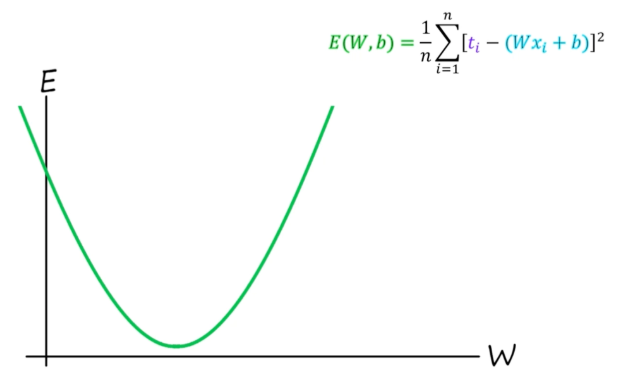  

어떻게 바닥으로 가는가? -> 미분값으 부호로 판별  

| 지금 $W$의 위치 | 접선 기울기 | 현재값 − 기울기 | 결과 |
| --- | --- | --- | --- |
| 최솟값 오른쪽 | 양수 | 현재값 − 양수 | $W$가 작아짐 → 왼쪽으로 |
| 최솟값 왼쪽 | 음수 | 현재값 − 음수 | $W$가 커짐 → 오른쪽으로 |
| 최솟값 도달 | 0 | 현재값 − 0 | 멈춤 |  

$W <- W - \alpha\frac{\partial E}{\partial W}$ *$\alpha$ : 학습률*  

편향 b의 경우도 x축을 b로 바꾸면 같은 방식으로 찾을 수 있음!  

e.g. 짙은 안개(많은 데이터)때문에 산(손실함수) 속에서 길을 잃은 경우, 발밑 지면의 기울만 느낄 수 있다. 이때 골짜기로 빨리 내려가라면? 가장 가파른 쪽으로 한걸음씩 내려가면 된다! 이것이 경사하강법의 원리  


2. 학습률(Learning Rate, $\alpha$)  
방향을 정했다면, 얼마나 움직여야 하는가의 문제에 도착 (안개 낀 산에서 보폭에 해당)  

미분값을 그대로 뺀다면? -> 한번에 너무 많이 움직여 최소값을 지나고, 이후 같은 과정을 했을 때 또 지나는 문제 발생 가능  

그래서 미분값에 학습률을 곱해 이동량을 조절!  
$W <- W - \alpha\frac{\partial E}{\partial W}$  

- 학습률이 너무 작은 경우 : 수렴은 하지만 너무 오래 걸림  
- 학습률이 너무 큰 경우 : 수렴 못하고 발산(손실이 계속 증가)  
-> 적당한 학습률을 찾아야 한다!  

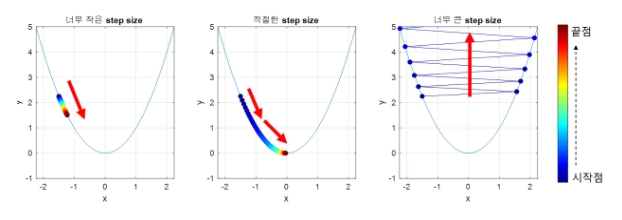  

그렇다면 학습률은 얼마로 설정해야하는가? -> 0.001 부터 시작(Adam의 기본값)  

**학습률은 개발자가 직접 설정하는 하이퍼파라미터**  
설정하는 방법  
1. 초기에 작은 값부터 시도 : 보통 0.01, 0.001, 0.0001을 경험적으로 시도  
2. 실험을 통해 조정 : 학습이 너무 느리면 늘리고, 발산하면 줄이며 여러 번 실험  

자동으로 찾는 방법  
- Learning Rate Scheduler : 학습과정에서 학습률을 자동으로 줄이거나 늘려줌  
- Grid Search, Random Search : 여러 학습률을 자동으로 실험하며 최적값을 찾아줌  

3. 배치, 에포크, 이터레이션  

> 배치(Batch) : 위 식의 $frac{\partial E}{\partial W}$를 구하기 위해 데이터를 나누어 넣는 과정  
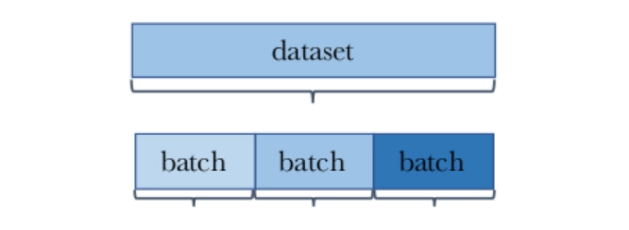 

- 학습과정에서 매개변수 조정을 위해 사용되는 데이터 묶음, 하이퍼 파라미터
- 배치 크기가 너무 크면 학습이 느려지고 메모리가 부족해짐  
- 배치 크기가 너무 작으면 가중치가 자주 업데이트 되어 학습이 불안정해짐  

> 에포크(Epoch) : 모든 데이터셋을 학습하는 횟수  
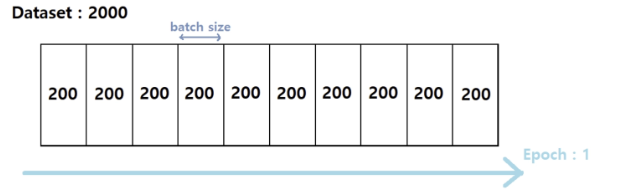  

> 이터레이션(Iteration) or 스텝(Step) : 한 번의 에포크를 끝내기 위해 필요한 배치의 수  
1 Epoch에서 다루는 데이터의 수 = 배치 크기 * 이터레이션  
-> 전체 데이터가 2,000일떄 배치 크기를 200으로 하면 이터레이션은 총 10  


4. 경사하강법의 종류  
    1. 배치 경사 하강법(Batch Gradient Descent)  
    오차를 구할 때 전체 데이터를 한 묶음으로 묶는다(Batch Size = Data Size)  

    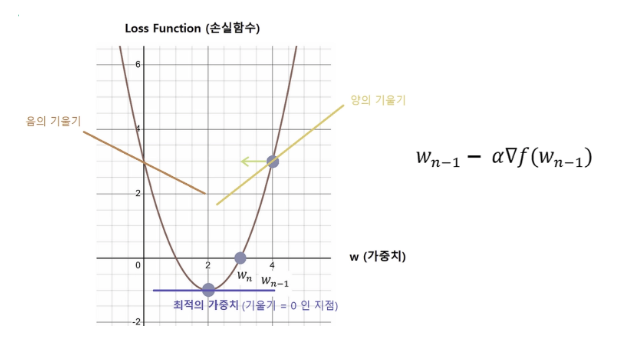  

    - 전체 데이터로 학습하므로 업데이트 횟수가 적음(1 Epoch당 1업데이트)  
    - 한 번에 처리하므로 메모리가 많이 필요  
    - 항상 같은 데이터에 대해 경사를 구하므로 수렴이 안정적  


    2. 확률적 경사하강법(Stochastic Gradient Descent, SGD)  
    기존 경사하강법의 단점? -> 전체 데이터를 계산하므로 시간이 오래 소요  

    매개 변수를 조정할 때 전체가 아니라 랜덤으로 선택된 하나의 데이터에 대해서만 계산  

    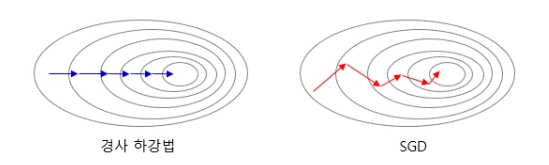  

    - 하나의 데이터만 메모리에 저장하면 되므로 자원이 적은 컴퓨터에서도 사용가능  
    - 매개변수의 변경폭이 불안정하고 정확도가 낮을 수 있음  


    3. 미니 배치 경사하강법(Mini-Batch Gradient Descent)  
    배치 크기가 1이면 정확도가 낮고, 전체 배치는 메모리가 부족한 문제 -> 이를 해결하기 위해 미니 배치 경사하강법 도입  

    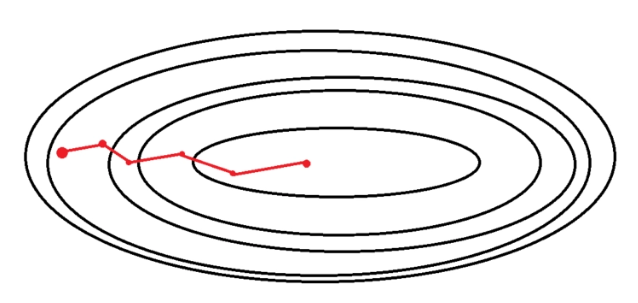  

    - 배치 크기를 적절히 지정하여 해당 개수만큼 매개변수 조정  
    - 전체 데이터보다 빠르고, 배치 크기 1보다 안정적 -> 가장 많이 사용  

    실무에서는 미니배치를 사용(model.fit()의 batch_size기본값이 32인 이유)



## 옵티마이저(Optimizer)  

If, 손실함수의 그래프가 앞선 그래프처럼 아래로 볼록이라면 경사하강법으로 반드시 바닥에 도달(MSE, RMSE는 볼록함수)  
But, 딥러닝의 손실함수는 항상 그런것은 아니다! 층이 여러개이며, 어떤 모양일지도 예측 불가!  

경사하강법에선 기울기가 0이면 stop, 그러나 Global Minimum이 아닌 Local Minimum에서도 기울기는 0 -> 여기 갇히는 문제 발생 가능
And, 작은 기울기에선 조금씩 움직이므로 빠져나오는데 한참 걸림  

-> 경사하강법을 더 스마트하게 굴릴방법이 필요! : 옵티마이저  

1. 모멘텀(Momentum) : 변수가 가던 방향으로 계속 가도록 속도를 추가  
기존 경사하강법은 이전 기울기를 다 잊어버리는 방식이었으나, 모멘텀을 도입하여 이전에 가던 방향을 기억하도록 관성을 부여  
e.g. 관성을 가진 공처럼 이전 방향을 참고하면 더 부드럽고 빠르게 작은 언덕도 넘어갈 수 있다!  

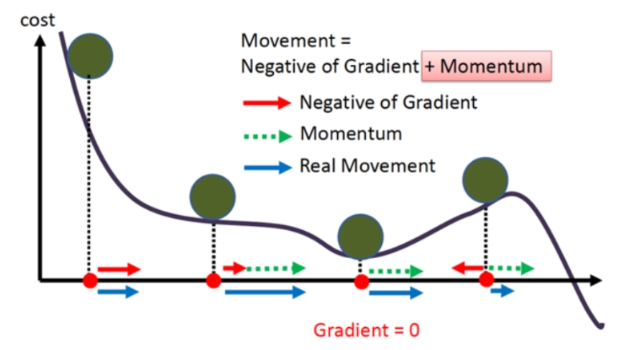   


2. 알엠에스프롭(RMSProp)  
기존 경사하강법의 또 다른 문제? 기울기가 큰 방향에서는 너무 많이, 작은 방향에서는 너무 조금 이동  
-> 각 방향마다 학습률을 따로 조정해서 안정적이고 빠르게 학습하도록 함  
즉, RMSProp은 최근 기울기를 참고하여 급한 경사에선 속도를 줄이고, 완만한 경사에서는 속도를 유지하거나 증가시킨다  


3. 아담(Adam) : RMSProp과 Momentum을 합친, '방향과 스텝 사이즈를 적절하게 합친 방법'  
각 파라미터의 1차 모멘트(기울기 평균)와 2차 모멘트(기울기 제곱 평균)를 사용하여 학습률을 조정  

**정리(어떤 케이스에서 무엇을 사용하는가)**  
| 이럴 때 | 이걸 쓰세요 | 왜 |
| --- | --- | --- |
| 잘 모르겠다 / 대부분의 경우 | Adam | 방향과 보폭을 둘 다 잡음. 사실상 기본값 |
| 학습이 자꾸 한쪽으로 튄다 | 모멘텀 | 방향을 안정화 |
| 파라미터마다 기울기 크기 차이가 크다 | RMSProp | 방향별로 학습률을 따로 조정 |

